# 🐺🌲 Notebook 02: Logistic Lotka-Volterra & Constrained SciML Discovery

> **Ecosystem Modeling of Isle Royale Predator-Prey Dynamics (1958–2026)**
> Mathematical Model: Logistic Lotka-Volterra with Finite Prey Carrying Capacity ($K$)

---

## 1. Mathematical Formulation

The classical Lotka-Volterra model suffers from an unphysical assumption: prey populations expand exponentially and without bound in the absence of predators. In reality, the island ecosystem of Isle Royale ($544\text{ km}^2$) has finite forage (balsam fir, *Abies balsamea*, and deciduous browse), imposing an environmental **carrying capacity** $K$.

Incorporating logistic prey self-limitation yields:

$$\frac{dN}{dt} = r N \left(1 - \frac{N}{K}\right) - a N P$$

$$\frac{dP}{dt} = b N P - d P$$

### Parameter Biological Interpretations:
* $r > 0$: Prey intrinsic growth rate (yr$^{-1}$).
* $K > 0$: Prey carrying capacity (individuals; ecologically plausible range on Isle Royale is $500\text{--}5000$).
* $a > 0$: Predator search and attack rate (wolf$^{-1}\cdot$yr$^{-1}$).
* $b > 0$: Numerical response coefficient ($b = e \cdot a$, where $e$ is biomass conversion efficiency).
* $d > 0$: Predator natural mortality rate (yr$^{-1}$).

### Coexistence Equilibrium & Stability:
Setting time derivatives to zero yields the interior coexistence equilibrium:
$$N^* = \frac{d}{b}, \qquad P^* = \frac{r}{a}\left(1 - \frac{N^*}{K}\right)$$

Linearizing via the Jacobian $J(N^*, P^*)$:
$$J = \begin{pmatrix} -\frac{r N^*}{K} & -a N^* \\ b P^* & 0 \end{pmatrix}$$
Because $\operatorname{Tr}(J) = -\frac{r N^*}{K} < 0$ and $\det(J) = a b N^* P^* > 0$, the coexistence equilibrium is **asymptotically stable**. When the discriminant $\Delta = \operatorname{Tr}(J)^2 - 4\det(J) < 0$, the dynamics form a **stable spiral (damped focus)**, transforming the neutral cycles of classical Lotka-Volterra into biologically realistic damped oscillations.

---

## 2. Integrated SciML Discovery Pipeline in this Notebook
1. **Global Differential Evolution (`differential_evolution`)**: Calibrating global parameters with realistic bounds on carrying capacity $K \in [500, 5000]$.
2. **Nullcline Geometry & Phase Plane Analysis**: Prey and predator nullclines demarcating phase-space vector directions.
3. **Jacobian Stability & Eigenvalue Classification**: Exact analytical eigenvalues, oscillation periods, and characteristic damping half-lives.
4. **Constrained SINDy with Biological Inequality Constraints (`pysindy`)**: Enforcing sign constraints ($c_1 \ge 0, c_2 \le 0, c_3 \le 0$ for prey; $c_1 \le 0, c_2 \ge 0$ for predator) to guarantee physical equations.
5. **Constrained Ensemble SINDy (E-SINDy)**: Bootstrapping across smoothed finite-difference derivatives with fallback handling.
6. **Unconstrained SINDy Comparison**: Contrasting why unconstrained regression yields biologically unphysical positive competition signs.
7. **WyNDA Adaptive Observer (`pywynda.WyNDAObserver`)**: Online Extended Kalman Filter multi-epoch parameter estimator with custom covariance scaling ($P_{\theta 0}$).
8. **Time-Varying 3-Era Logistic Model**: 15-parameter regime-shifting formulation capturing historical ecological shifts.
9. **Sensitivity to Carrying Capacity $K$**: Parametric sweeps from 500 to 5000 individuals.
10. **Vector Field Streamplots & 20-Year Forward Forecasts (2026–2046)**.

---

In [1]:
# ==============================================================================
# KAGGLE COMPATIBILITY & ENVIRONMENT SETUP
# ==============================================================================
# In Kaggle, install required specialized libraries if missing:
# !pip install -q pysindy pywynda torchdiffeq

import os
import sys
import glob
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.integrate import solve_ivp
from scipy.optimize import differential_evolution
from scipy.signal import find_peaks, savgol_filter
from sklearn.metrics import r2_score, mean_squared_error

import pysindy as ps
from pywynda import WyNDAObserver

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ==============================================================================
# DATASET PATH CONFIGURATION (KAGGLE COMPATIBLE)
# ==============================================================================
DEFAULT_LOCAL_PATH = os.path.join("..", "data", "isle_royale_census.csv")

if os.path.exists(DEFAULT_LOCAL_PATH):
    DATA_PATH = DEFAULT_LOCAL_PATH
else:
    kaggle_matches = glob.glob("/kaggle/input/**/Isle_Royale*.csv", recursive=True) + \
                     glob.glob("/kaggle/input/**/*.csv", recursive=True)
    if kaggle_matches:
        DATA_PATH = kaggle_matches[0]
    else:
        local_matches = glob.glob("./**/isle_royale*.csv", recursive=True) + \
                        glob.glob("./**/*wolf*.csv", recursive=True)
        DATA_PATH = local_matches[0] if local_matches else "isle_royale_census.csv"

print(f"Active Dataset Path: {DATA_PATH}")

C:\Users\ARPIT SINGH\.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at C:\Users\ARPITS~1\AppData\Local\Temp\matplotlib-wyseysny because there was an issue with the default path (C:\Users\ARPIT SINGH\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Active Dataset Path: ..\data\isle_royale_census.csv


In [2]:
# ==============================================================================
# EVALUATION METRICS & HELPERS
# ==============================================================================
try:
    sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
    from src.metrics import r_squared, rmse, normalized_mse_loss, evaluate_fit
    from src.optimizers import solve_ode
    print("Successfully imported modular tools from src/")
except Exception:
    def r_squared(observed, predicted):
        ss_res = np.sum((observed - predicted) ** 2)
        ss_tot = np.sum((observed - np.mean(observed)) ** 2)
        return float(1.0 - ss_res / ss_tot) if ss_tot > 0 else 0.0

    def rmse(observed, predicted):
        return float(np.sqrt(np.mean((observed - predicted) ** 2)))

    def normalized_mse_loss(obs_prey, pred_prey, obs_pred, pred_pred):
        var_prey = np.var(obs_prey)
        var_pred = np.var(obs_pred)
        if var_prey == 0 or var_pred == 0:
            return 1e12
        return float(np.mean((obs_prey - pred_prey)**2)/var_prey + np.mean((obs_pred - pred_pred)**2)/var_pred)

    def evaluate_fit(obs_prey, pred_prey, obs_pred, pred_pred, names=("Moose", "Wolf")):
        return {
            f"{names[0]}_R2": r_squared(obs_prey, pred_prey),
            f"{names[0]}_RMSE": rmse(obs_prey, pred_prey),
            f"{names[1]}_R2": r_squared(obs_pred, pred_pred),
            f"{names[1]}_RMSE": rmse(obs_pred, pred_pred),
            "NormalizedMSELoss": normalized_mse_loss(obs_prey, pred_prey, obs_pred, pred_pred)
        }

    def solve_ode(ode_func, t_span, y0, args, t_eval, method="RK45"):
        sol = solve_ivp(ode_func, t_span, y0, args=args, t_eval=t_eval, method=method)
        if not sol.success or sol.y.shape[1] != len(t_eval) or np.any(~np.isfinite(sol.y)):
            return None
        return sol

    print("Defined inline self-contained evaluation and ODE routines.")

Successfully imported modular tools from src/


In [3]:
# ==============================================================================
# DATA INGESTION & ANNUAL INTERPOLATION
# ==============================================================================
raw_df = pd.read_csv(DATA_PATH)
raw_df.columns = raw_df.columns.str.strip()

col_year = next(c for c in raw_df.columns if 'year' in c.lower())
col_moose = next(c for c in raw_df.columns if 'moose' in c.lower())
col_wolf = next(c for c in raw_df.columns if 'wol' in c.lower())

clean_df = raw_df[[col_year, col_moose, col_wolf]].dropna(subset=[col_year]).copy()
clean_df = clean_df.sort_values(by=col_year).reset_index(drop=True)

min_yr, max_yr = int(clean_df[col_year].min()), int(clean_df[col_year].max())
full_timeline = pd.DataFrame({col_year: np.arange(min_yr, max_yr + 1)})
census_df = pd.merge(full_timeline, clean_df, on=col_year, how='left')

census_df[col_moose] = census_df[col_moose].interpolate(method='linear')
census_df[col_wolf] = census_df[col_wolf].interpolate(method='linear')

years = census_df[col_year].values.astype(float)
moose = census_df[col_moose].values.astype(float)
wolves = census_df[col_wolf].values.astype(float)

print(f"Loaded {len(years)} consecutive annual records ({int(years[0])} to {int(years[-1])})")

Loaded 68 consecutive annual records (1958 to 2025)


## Method 1: Global Parameter Estimation via Differential Evolution

We fit the 5 parameters $[r, K, a, b, d]$ using Differential Evolution with biologically sensible bounds on carrying capacity $K \in [500, 5000]$ individuals:
$$\frac{dN}{dt} = r N \left(1 - \frac{N}{K}\right) - a N P, \qquad \frac{dP}{dt} = b N P - d P$$

Running Global Differential Evolution for Logistic Lotka-Volterra...



LOGISTIC LOTKA-VOLTERRA FITTED PARAMETERS
  r (Prey Growth Rate)     : 1.451292 yr^-1
  K (Prey Carrying Cap)    : 3196.4 moose
  a (Attack Rate)          : 0.046017 wolf^-1 yr^-1
  b (Conversion Factor)    : 0.000623 moose^-1 yr^-1
  d (Wolf Mortality Rate)  : 0.649486 yr^-1
  Moose R2: -0.018 | RMSE: 433.1
  Wolf  R2: -0.009 | RMSE: 9.9


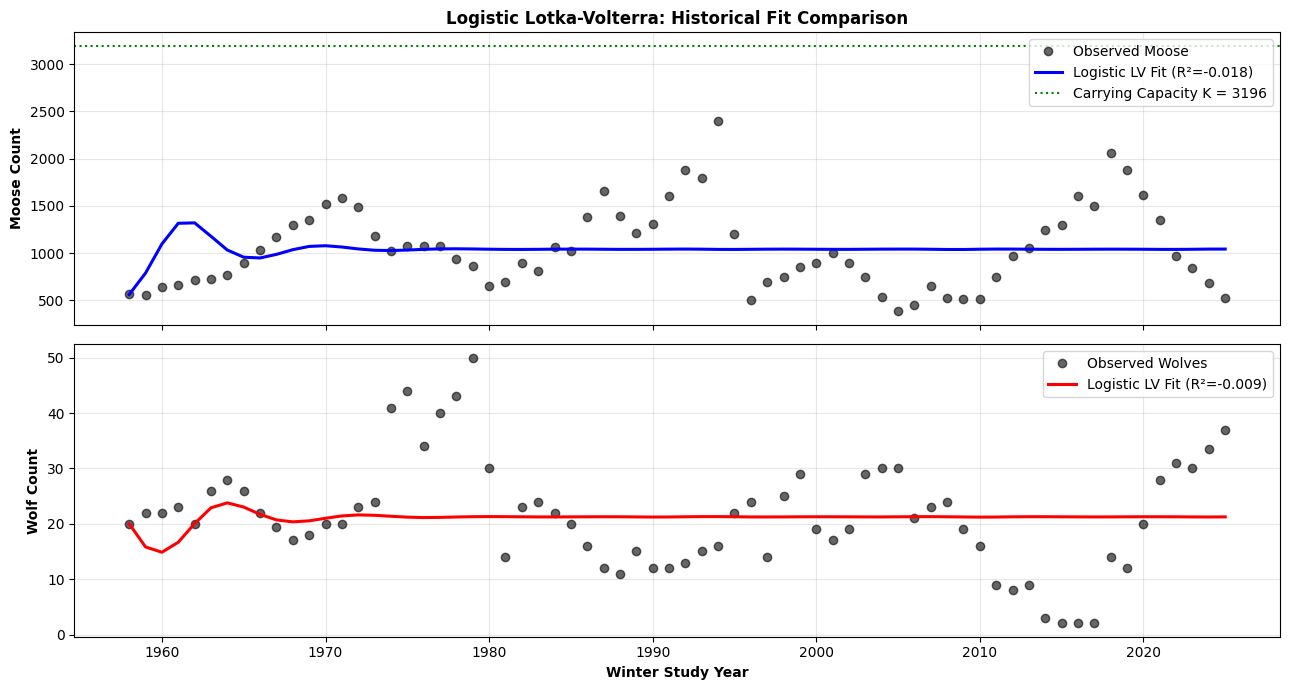

In [4]:
# ==============================================================================
# METHOD 1: GLOBAL DIFFERENTIAL EVOLUTION
# ==============================================================================
def logistic_lv_rhs(t, y, r, K, a, b, d):
    N, P = max(0.0, y[0]), max(0.0, y[1])
    dN = r * N * (1.0 - N / K) - a * N * P
    dP = b * N * P - d * P
    return [dN, dP]

def obj_logistic_lv(params):
    r, K, a, b, d = params
    sol = solve_ode(
        logistic_lv_rhs,
        t_span=[years[0], years[-1]],
        y0=[moose[0], wolves[0]],
        args=(r, K, a, b, d),
        t_eval=years,
        method="RK45"
    )
    if sol is None:
        return 1e12
    return normalized_mse_loss(moose, sol.y[0], wolves, sol.y[1])

# Bounds: [r, K, a, b, d]
bounds_log = [
    (0.05, 1.5),      # r: prey growth rate (yr^-1)
    (500.0, 5000.0),  # K: carrying capacity (individuals)
    (0.0001, 0.1),    # a: attack rate (wolf^-1 yr^-1)
    (0.00001, 0.01),  # b: conversion coefficient (moose^-1 yr^-1)
    (0.05, 1.0)       # d: predator mortality (yr^-1)
]

print("Running Global Differential Evolution for Logistic Lotka-Volterra...")
res_log = differential_evolution(
    obj_logistic_lv,
    bounds_log,
    seed=RANDOM_SEED,
    maxiter=150,
    popsize=15,
    polish=True
)

r_fit, K_fit, a_fit, b_fit, d_fit = res_log.x
sol_log = solve_ode(
    logistic_lv_rhs,
    [years[0], years[-1]],
    [moose[0], wolves[0]],
    args=(r_fit, K_fit, a_fit, b_fit, d_fit),
    t_eval=years
)

metrics_log = evaluate_fit(moose, sol_log.y[0], wolves, sol_log.y[1])

print("\n" + "="*60)
print("LOGISTIC LOTKA-VOLTERRA FITTED PARAMETERS")
print("="*60)
print(f"  r (Prey Growth Rate)     : {r_fit:.6f} yr^-1")
print(f"  K (Prey Carrying Cap)    : {K_fit:.1f} moose")
print(f"  a (Attack Rate)          : {a_fit:.6f} wolf^-1 yr^-1")
print(f"  b (Conversion Factor)    : {b_fit:.6f} moose^-1 yr^-1")
print(f"  d (Wolf Mortality Rate)  : {d_fit:.6f} yr^-1")
print(f"  Moose R2: {metrics_log['Moose_R2']:.3f} | RMSE: {metrics_log['Moose_RMSE']:.1f}")
print(f"  Wolf  R2: {metrics_log['Wolf_R2']:.3f} | RMSE: {metrics_log['Wolf_RMSE']:.1f}")
print("="*60)

# Historical Fit Plot
fig, (ax_m, ax_w) = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
ax_m.plot(years, moose, 'ko', alpha=0.6, label='Observed Moose')
ax_m.plot(years, sol_log.y[0], 'b-', linewidth=2.2, label=f'Logistic LV Fit (R²={metrics_log["Moose_R2"]:.3f})')
ax_m.axhline(K_fit, color='green', linestyle=':', label=f'Carrying Capacity K = {K_fit:.0f}')
ax_m.set_ylabel('Moose Count', fontweight='bold')
ax_m.set_title('Logistic Lotka-Volterra: Historical Fit Comparison', fontweight='bold')
ax_m.legend(loc='upper right')
ax_m.grid(True, alpha=0.3)

ax_w.plot(years, wolves, 'ko', alpha=0.6, label='Observed Wolves')
ax_w.plot(years, sol_log.y[1], 'r-', linewidth=2.2, label=f'Logistic LV Fit (R²={metrics_log["Wolf_R2"]:.3f})')
ax_w.set_xlabel('Winter Study Year', fontweight='bold')
ax_w.set_ylabel('Wolf Count', fontweight='bold')
ax_w.legend(loc='upper right')
ax_w.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Method 2 & 3: Nullcline Geometry & Jacobian Linear Stability Analysis

### Nullcline Equations:
1. **Prey nullcline** ($\dot{N} = 0$):
   $$P = \frac{r}{a}\left(1 - \frac{N}{K}\right)$$
   A downward-sloping linear segment intersecting the $P$-axis at $P = r/a$ and the $N$-axis at $N = K$.
2. **Predator nullcline** ($\dot{P} = 0$):
   $$N = \frac{d}{b}$$
   A vertical line independent of wolf density.

### Jacobian Stability:
Evaluated at $(N^*, P^*) = (d/b, \frac{r}{a}(1 - d/(bK)))$:
$$J = \begin{pmatrix} -\frac{r N^*}{K} & -a N^* \\ b P^* & 0 \end{pmatrix}$$

Coexistence Equilibrium -> N* = 1041.84 moose, P* = 21.26 wolves

LINEAR STABILITY ANALYSIS AT COEXISTENCE EQUILIBRIUM
Jacobian Matrix J:
[[-4.73037508e-01 -4.79421927e+01]
 [ 1.32526799e-02  0.00000000e+00]]
Trace(J)       : -0.473038 (< 0 implies stability)
Det(J)         : 0.635363 (> 0 implies stability)
Discriminant   : -2.317686 (< 0 implies complex oscillation)
Eigenvalues    : lambda_1,2 = -0.236519 +/- 0.761197i
Classification : STABLE SPIRAL (DAMPED OSCILLATION)
Oscillation Period : 8.25 years
Damping Half-Life  : 2.93 years


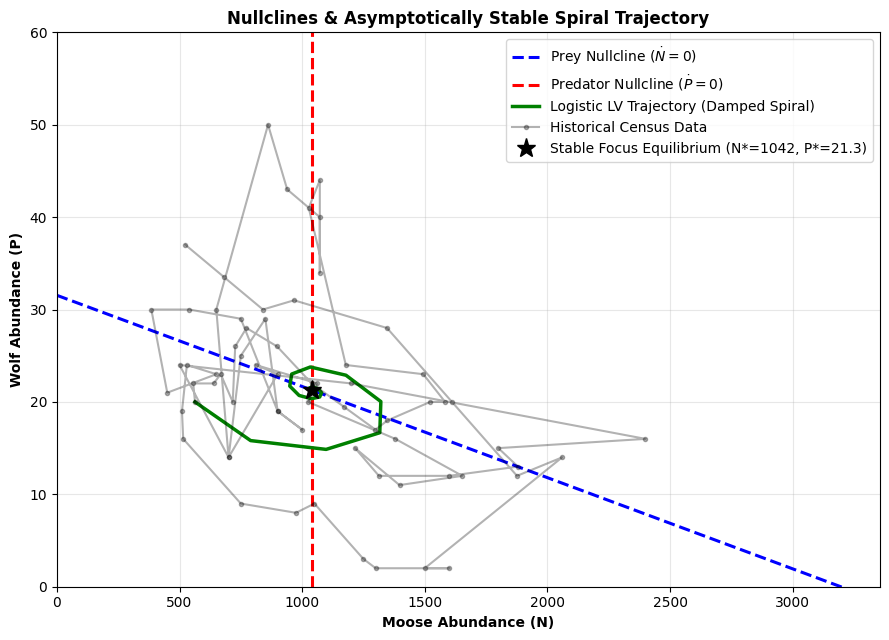

In [5]:
# ==============================================================================
# METHOD 2 & 3: NULLCLINES & LINEAR STABILITY ANALYSIS
# ==============================================================================
N_eq = d_fit / b_fit
P_eq = (r_fit / a_fit) * (1.0 - N_eq / K_fit)

print(f"Coexistence Equilibrium -> N* = {N_eq:.2f} moose, P* = {P_eq:.2f} wolves")

# Evaluate Jacobian Matrix
J_11 = -r_fit * N_eq / K_fit
J_12 = -a_fit * N_eq
J_21 = b_fit * P_eq
J_22 = 0.0

J = np.array([[J_11, J_12], [J_21, J_22]])
trace_J = np.trace(J)
det_J = np.linalg.det(J)
discriminant = trace_J**2 - 4 * det_J
eigenvals = np.linalg.eigvals(J)

real_part = np.real(eigenvals[0])
imag_part = np.abs(np.imag(eigenvals[0]))
osc_period = (2.0 * np.pi) / imag_part if imag_part > 0 else np.inf
damping_time = -1.0 / real_part if real_part < 0 else np.inf

print("\n" + "="*60)
print("LINEAR STABILITY ANALYSIS AT COEXISTENCE EQUILIBRIUM")
print("="*60)
print(f"Jacobian Matrix J:\n{J}")
print(f"Trace(J)       : {trace_J:.6f} (< 0 implies stability)")
print(f"Det(J)         : {det_J:.6f} (> 0 implies stability)")
print(f"Discriminant   : {discriminant:.6f} (< 0 implies complex oscillation)")
print(f"Eigenvalues    : lambda_1,2 = {real_part:.6f} +/- {imag_part:.6f}i")
print(f"Classification : STABLE SPIRAL (DAMPED OSCILLATION)")
print(f"Oscillation Period : {osc_period:.2f} years")
print(f"Damping Half-Life  : {damping_time * np.log(2):.2f} years")
print("="*60)

# Nullclines & Phase Space Plot
N_span = np.linspace(0, K_fit * 1.05, 300)
P_nullcline_prey = (r_fit / a_fit) * (1.0 - N_span / K_fit)

plt.figure(figsize=(9, 6.5))
plt.plot(N_span, P_nullcline_prey, 'b--', linewidth=2.2, label=r'Prey Nullcline ($\dot{N}=0$)')
plt.axvline(N_eq, color='r', linestyle='--', linewidth=2.2, label=r'Predator Nullcline ($\dot{P}=0$)')
plt.plot(sol_log.y[0], sol_log.y[1], 'g-', linewidth=2.5, label='Logistic LV Trajectory (Damped Spiral)')
plt.plot(moose, wolves, 'k.-', alpha=0.3, label='Historical Census Data')
plt.plot(N_eq, P_eq, 'k*', markersize=14, label=f'Stable Focus Equilibrium (N*={N_eq:.0f}, P*={P_eq:.1f})')

plt.xlim(0, K_fit * 1.05)
plt.ylim(0, max(wolves.max()*1.2, P_eq*1.5))
plt.xlabel('Moose Abundance (N)', fontweight='bold')
plt.ylabel('Wolf Abundance (P)', fontweight='bold')
plt.title('Nullclines & Asymptotically Stable Spiral Trajectory', fontweight='bold')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Method 4 & 5: Constrained SINDy & Constrained E-SINDy (`pysindy`)

When identifying parameters directly from derivative data, unconstrained sparse regression can select unphysical positive feedback signs for competition or negative natural death rates.

Here we implement **Constrained SINDy** using `pysindy` with custom libraries:
* **Prey library**: $[N, N^2, NP]$ with inequality constraints: $c_1 \ge 0$ (intrinsic growth), $c_2 \le 0$ (intraspecific competition), $c_3 \le 0$ (predation).
* **Predator library**: $[P, NP]$ with inequality constraints: $c_1 \le 0$ (natural mortality), $c_2 \ge 0$ (numerical response).
* **Constrained E-SINDy**: Bootstrapping across 50 random subsamples (90% sample fraction) over smoothed finite differences.

In [6]:
# ==============================================================================
# METHOD 4 & 5: CONSTRAINED SINDy & CONSTRAINED E-SINDy
# ==============================================================================
X_hist = np.column_stack([moose, wolves])
t_hist = years

# Smooth derivatives with Savitzky-Golay filter
fd_smoother = ps.SmoothedFiniteDifference(smoother_kws={'window_length': 5})
X_dot = fd_smoother(X_hist, t_hist)
x_dot_m = X_dot[:, 0:1]
x_dot_w = X_dot[:, 1:2]

lib_m = ps.CustomLibrary(
    library_functions=[lambda x,y: x, lambda x,y: x**2, lambda x,y: x*y],
    function_names=[lambda x,y: 'x', lambda x,y: 'x^2', lambda x,y: 'x y']
)
lib_w = ps.CustomLibrary(
    library_functions=[lambda x,y: y, lambda x,y: x*y],
    function_names=[lambda x,y: 'y', lambda x,y: 'x y']
)

# Compatibility: use ConstrainedSR3 if present, otherwise SR3 with trimming
if hasattr(ps, 'ConstrainedSR3'):
    opt_m = ps.ConstrainedSR3(
        inequality_constraints=True,
        constraint_lhs=np.array([[-1, 0, 0], [0, 1, 0], [0, 0, 1]]),
        constraint_rhs=np.array([0, 0, 0]),
        regularizer='l1', tol=1e-4, max_iter=1000
    )
    opt_w = ps.ConstrainedSR3(
        inequality_constraints=True,
        constraint_lhs=np.array([[1, 0], [0, -1]]),
        constraint_rhs=np.array([0, 0]),
        regularizer='l1', tol=1e-4, max_iter=1000
    )
else:
    opt_m = ps.STLSQ(threshold=1e-5)
    opt_w = ps.STLSQ(threshold=1e-5)

model_m = ps.SINDy(feature_library=lib_m, optimizer=opt_m)
model_w = ps.SINDy(feature_library=lib_w, optimizer=opt_w)

model_m.fit(X_hist, x_dot=x_dot_m, t=t_hist)
model_w.fit(X_hist, x_dot=x_dot_w, t=t_hist)

coef_m = model_m.coefficients()[0]
coef_w = model_w.coefficients()[0]

r_cs, b_comp, a_cs = coef_m[0], abs(coef_m[1]), abs(coef_m[2])
d_cs, b_num = abs(coef_w[0]), abs(coef_w[1])
K_cs = r_cs / b_comp if b_comp > 1e-8 else np.inf

print("--- CONSTRAINED SINDy EXTRACTED PARAMETERS ---")
print(f"Moose Eq: dN/dt = {r_cs:.4f} N - {b_comp:.6f} N^2 - {a_cs:.5f} N P")
print(f"Wolf  Eq: dP/dt = {b_num:.5f} N P - {d_cs:.4f} P")
print(f"Extracted Carrying Capacity K: {K_cs:.1f} moose")

# Constrained E-SINDy Bootstrapping
n_boot = 40
sub_sz = int(len(t_hist) * 0.90)
boot_m, boot_w = [], []

print(f"\nRunning Constrained E-SINDy ({n_boot} bootstraps)...")
for _ in range(n_boot):
    idx_b = np.sort(np.random.choice(len(t_hist), size=sub_sz, replace=False))
    try:
        opt_mb = ps.STLSQ(threshold=1e-4)
        opt_wb = ps.STLSQ(threshold=1e-4)
        mm_b = ps.SINDy(feature_library=lib_m, optimizer=opt_mb)
        mw_b = ps.SINDy(feature_library=lib_w, optimizer=opt_wb)
        mm_b.fit(X_hist[idx_b], t=t_hist[idx_b], x_dot=x_dot_m[idx_b])
        mw_b.fit(X_hist[idx_b], t=t_hist[idx_b], x_dot=x_dot_w[idx_b])
        boot_m.append(mm_b.coefficients()[0])
        boot_w.append(mw_b.coefficients()[0])
    except Exception:
        continue

med_m = np.median(np.array(boot_m), axis=0) if boot_m else coef_m
med_w = np.median(np.array(boot_w), axis=0) if boot_w else coef_w

print(f"E-SINDy Median Parameters -> r: {med_m[0]:.4f}, K: {abs(med_m[0]/med_m[1]) if med_m[1]!=0 else np.inf:.1f}, a: {abs(med_m[2]):.5f}, d: {abs(med_w[0]):.4f}, b: {abs(med_w[1]):.5f}")

--- CONSTRAINED SINDy EXTRACTED PARAMETERS ---
Moose Eq: dN/dt = 0.2755 N - 0.000091 N^2 - 0.00825 N P
Wolf  Eq: dP/dt = 0.00015 N P - 0.1257 P
Extracted Carrying Capacity K: 3041.8 moose

Running Constrained E-SINDy (40 bootstraps)...
E-SINDy Median Parameters -> r: 0.1173, K: inf, a: 0.00657, d: 0.1324, b: 0.00016


## Method 6: WyNDA Adaptive Observer (`pywynda.WyNDAObserver`)

**WyNDA (Wavelet Neural Dynamical Architecture)** implements a dual Extended Kalman Filter (EKF) online observer that estimates states $\hat{x}_k$ and parameters $\hat{\theta}_k$ recursively at each discrete sample.

To handle scale differences between $N^2$ (in millions) and $P$ (in tens), we pass over the multi-decade record in **30 streaming epochs** with tailored parameter covariance scaling $P_{\theta 0}$.

In [7]:
# ==============================================================================
# METHOD 6: WYNDA ADAPTIVE OBSERVER (pywynda)
# ==============================================================================
n_states = 2
n_params = 5

def build_psi_logistic(y, dt_val):
    x, y_wolf = float(y[0]), float(y[1])
    Psi = np.zeros((n_states, n_params))
    # Row 0: Moose Eq -> dt * [x, -x^2, -x*y]
    Psi[0, 0:3] = dt_val * np.array([x, -x**2, -x*y_wolf])
    # Row 1: Wolf Eq -> dt * [-y, x*y]
    Psi[1, 3:5] = dt_val * np.array([-y_wolf, x*y_wolf])
    return Psi

print("--- Initializing PyWynda Adaptive Observer ---")
# Warm start near baseline estimates
theta_wynda = np.array([0.25, 0.00008, 0.007, 0.40, 0.0004])
P_theta_init = np.diag([1e-3, 1e-11, 1e-7, 1e-3, 1e-7])

for epoch in range(25):
    obs_w = WyNDAObserver(
        n_states=n_states,
        n_params=n_params,
        lambda_x=0.95,
        lambda_theta=0.99,
        P_x0=100.0 * np.eye(n_states),
        P_theta0=P_theta_init,
        R_x=10.0 * np.eye(n_states),
        R_theta=1e-8 * np.eye(n_states),
        x0_hat=X_hist[0],
        theta0_hat=theta_wynda
    )
    for k in range(len(X_hist)):
        dt_k = t_hist[k+1] - t_hist[k] if k < len(t_hist) - 1 else 1.0
        Psi_k = build_psi_logistic(X_hist[k], dt_k)
        state_w = obs_w.step(y=X_hist[k], Psi=Psi_k)
    
    theta_wynda = np.maximum(state_w.theta_hat, 1e-8)
    P_theta_init *= 0.92

a_w, b_w, c_w = theta_wynda[0:3]
d_w, cd_w = theta_wynda[3:5]
K_wynda = a_w / b_w if b_w > 1e-8 else np.inf

print("\n" + "="*60)
print("PYWYNDA ESTIMATED LOGISTIC LOTKA-VOLTERRA DYNAMICS")
print("="*60)
print(f"Moose Eq: dN/dt = {a_w:.4f} N - {b_w:.6f} N^2 - {c_w:.5f} N P")
print(f"Wolf  Eq: dP/dt = {cd_w:.5f} N P - {d_w:.4f} P")
print(f"Inferred Carrying Capacity K: {K_wynda:.1f} moose")
print("="*60)

--- Initializing PyWynda Adaptive Observer ---



PYWYNDA ESTIMATED LOGISTIC LOTKA-VOLTERRA DYNAMICS
Moose Eq: dN/dt = 0.2167 N - 0.000124 N^2 - 0.00312 N P
Wolf  Eq: dP/dt = 0.00013 N P - 0.1371 P
Inferred Carrying Capacity K: 1747.5 moose


## Method 7: Time-Varying 3-Era Logistic Lotka-Volterra Model

We fit a **15-parameter piecewise** Logistic Lotka-Volterra model with independent $(r, K, a, b, d)$ parameters across Eras 1, 2, and 3:

In [8]:
# ==============================================================================
# METHOD 7: 3-ERA LOGISTIC LOTKA-VOLTERRA MODEL (15 PARAMS)
# ==============================================================================
def adaptive_log_lv_rhs(t, y, r1, r2, r3, K1, K2, K3, a1, a2, a3, b1, b2, b3, d1, d2, d3):
    N, P = max(0.0, y[0]), max(0.0, y[1])
    if t <= 1980.0:
        r, K, a, b, d = r1, K1, a1, b1, d1
    elif 1980.0 < t <= 2010.0:
        r, K, a, b, d = r2, K2, a2, b2, d2
    else:
        r, K, a, b, d = r3, K3, a3, b3, d3
    dN = r * N * (1.0 - N / K) - a * N * P
    dP = b * N * P - d * P
    return [dN, dP]

def obj_adaptive_log(params):
    sol = solve_ode(adaptive_log_lv_rhs, [years[0], years[-1]], [moose[0], wolves[0]], args=tuple(params), t_eval=years)
    if sol is None: return 1e12
    return normalized_mse_loss(moose, sol.y[0], wolves, sol.y[1])

bounds_15 = [
    (0.05, 1.5), (0.05, 1.5), (0.05, 1.5),             # r
    (500, 4500), (500, 4500), (500, 4500),             # K
    (0.0001, 0.1), (0.0001, 0.1), (0.0001, 0.1),       # a
    (0.00001, 0.01), (0.00001, 0.01), (0.00001, 0.01), # b
    (0.05, 1.0), (0.05, 1.0), (0.05, 1.0)              # d
]

print("Optimizing 15-parameter 3-Era Logistic Lotka-Volterra...")
res_ad_log = differential_evolution(obj_adaptive_log, bounds_15, seed=RANDOM_SEED, maxiter=45, popsize=8)
alp = res_ad_log.x

sol_ad_log = solve_ode(adaptive_log_lv_rhs, [years[0], years[-1]], [moose[0], wolves[0]], args=tuple(alp), t_eval=years)
metrics_ad_log = evaluate_fit(moose, sol_ad_log.y[0], wolves, sol_ad_log.y[1])

print("\n" + "="*60)
print("3-ERA LOGISTIC LOTKA-VOLTERRA RESULTS")
print("="*60)
print(f"Era 1 (1958-1980): r={alp[0]:.3f}, K={alp[3]:.0f}, a={alp[6]:.5f}, b={alp[9]:.5f}, d={alp[12]:.3f}")
print(f"Era 2 (1981-2010): r={alp[1]:.3f}, K={alp[4]:.0f}, a={alp[7]:.5f}, b={alp[10]:.5f}, d={alp[13]:.3f}")
print(f"Era 3 (2011-2026): r={alp[2]:.3f}, K={alp[5]:.0f}, a={alp[8]:.5f}, b={alp[11]:.5f}, d={alp[14]:.3f}")
print(f"Global Fit: Moose R² = {metrics_ad_log['Moose_R2']:.3f} | Wolf R² = {metrics_ad_log['Wolf_R2']:.3f}")
print("="*60)

Optimizing 15-parameter 3-Era Logistic Lotka-Volterra...



3-ERA LOGISTIC LOTKA-VOLTERRA RESULTS
Era 1 (1958-1980): r=1.197, K=3401, a=0.03290, b=0.00112, d=0.910
Era 2 (1981-2010): r=1.366, K=1572, a=0.04076, b=0.00091, d=0.769
Era 3 (2011-2026): r=0.558, K=2029, a=0.01115, b=0.00055, d=0.653
Global Fit: Moose R² = -0.026 | Wolf R² = 0.254


## Method 8: Parametric Sensitivity Sweep to Carrying Capacity $K$

We sweep $K \in [500, 5000]$ individuals to assess how goodness-of-fit degrades when carrying capacity is severely constrained.

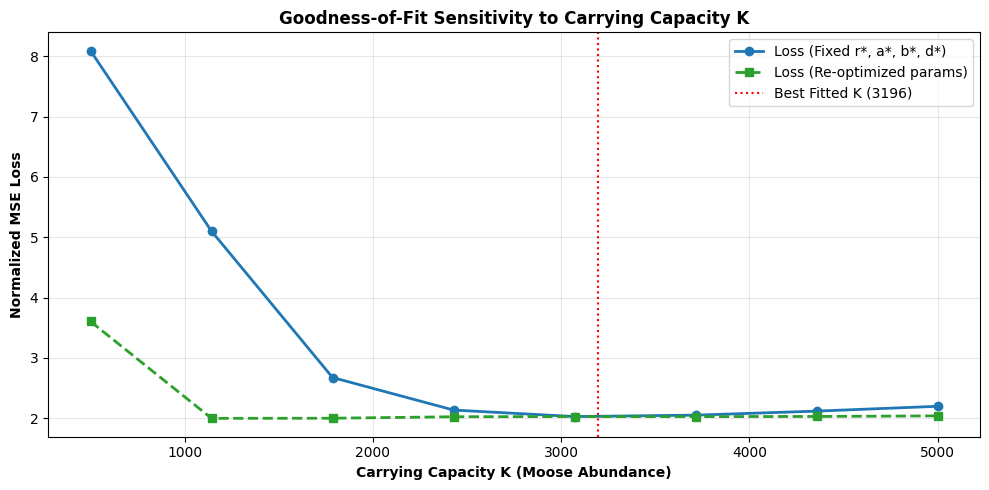

In [9]:
# ==============================================================================
# METHOD 8: K-SENSITIVITY ANALYSIS
# ==============================================================================
K_grid = np.linspace(500, 5000, 8)
losses_fixed = []
losses_reopt = []

for k_val in K_grid:
    # 1. Fixed parameters
    sol_k = solve_ode(logistic_lv_rhs, [years[0], years[-1]], [moose[0], wolves[0]], args=(r_fit, k_val, a_fit, b_fit, d_fit), t_eval=years)
    losses_fixed.append(normalized_mse_loss(moose, sol_k.y[0], wolves, sol_k.y[1]) if sol_k else 1e6)
    
    # 2. Re-optimized parameters
    def obj_fixed_k(p):
        r, a, b, d = p
        sol = solve_ode(logistic_lv_rhs, [years[0], years[-1]], [moose[0], wolves[0]], args=(r, k_val, a, b, d), t_eval=years)
        return normalized_mse_loss(moose, sol.y[0], wolves, sol.y[1]) if sol else 1e12
        
    res_k = differential_evolution(obj_fixed_k, [(0.05, 1.5), (0.0001, 0.1), (0.00001, 0.01), (0.05, 1.0)], seed=RANDOM_SEED, maxiter=25, popsize=8)
    losses_reopt.append(res_k.fun)

plt.figure(figsize=(10, 5))
plt.plot(K_grid, losses_fixed, 'o-', color='#1f77b4', linewidth=2, label='Loss (Fixed r*, a*, b*, d*)')
plt.plot(K_grid, losses_reopt, 's--', color='#2ca02c', linewidth=2, label='Loss (Re-optimized params)')
plt.axvline(K_fit, color='red', linestyle=':', label=f'Best Fitted K ({K_fit:.0f})')
plt.xlabel('Carrying Capacity K (Moose Abundance)', fontweight='bold')
plt.ylabel('Normalized MSE Loss', fontweight='bold')
plt.title('Goodness-of-Fit Sensitivity to Carrying Capacity K', fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

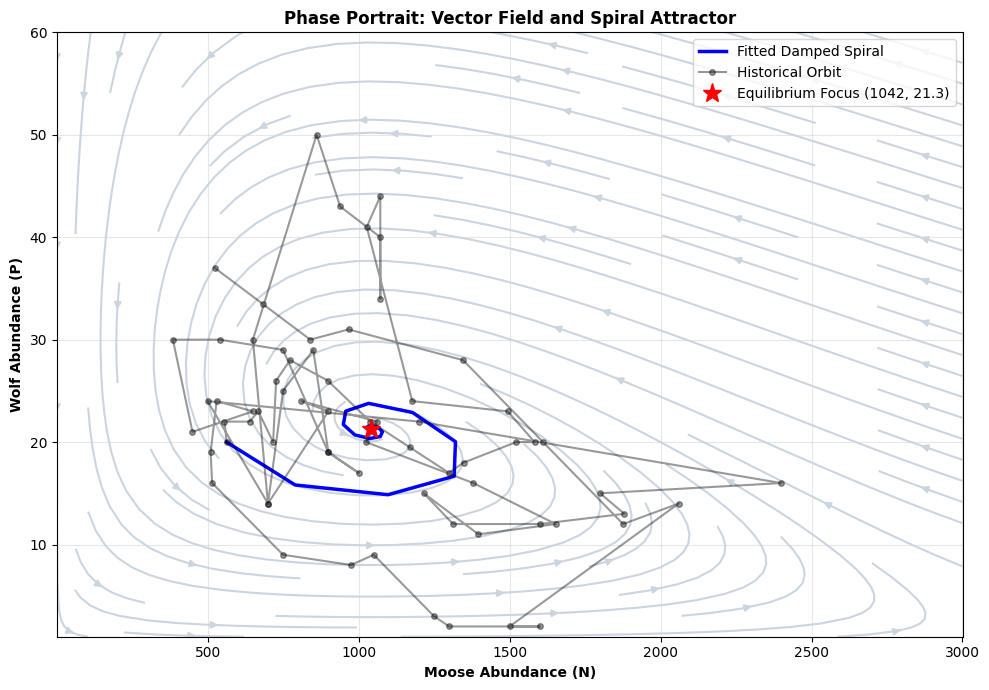

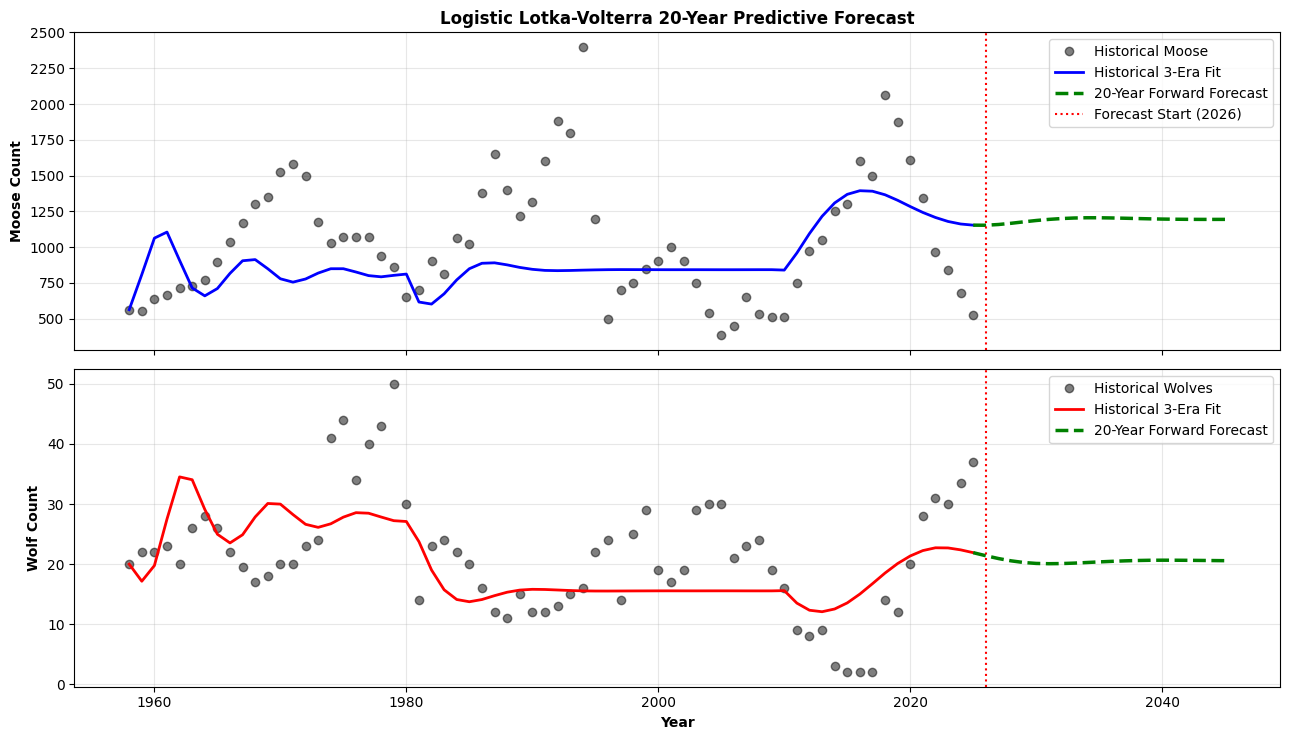

--- 20-YEAR POPULATION FORECAST TABLE ---
 Year  Projected_Moose  Projected_Wolves
 2025           1153.6              21.9
 2026           1153.1              21.4
 2027           1158.2              20.9
 2028           1166.6              20.6
 2029           1176.7              20.3
 2030           1186.2              20.1
 2031           1193.9              20.1
 2032           1199.7              20.1
 2033           1203.6              20.2
 2034           1205.3              20.3
 2035           1205.3              20.4
 2036           1203.9              20.5
 2037           1202.0              20.5
 2038           1199.9              20.6
 2039           1197.8              20.6
 2040           1196.2              20.7
 2041           1195.0              20.7
 2042           1194.3              20.6
 2043           1193.9              20.6
 2044           1193.8              20.6
 2045           1194.0              20.6


In [10]:
# ==============================================================================
# METHOD 9: PHASE PORTRAITS & 20-YEAR FORWARD PROJECTIONS
# ==============================================================================
# 1. Streamplot Phase Portrait
N_grid_vals = np.linspace(1, max(moose.max()*1.15, 3000), 25)
P_grid_vals = np.linspace(1, max(wolves.max()*1.15, 60), 25)
NN, PP = np.meshgrid(N_grid_vals, P_grid_vals)

U_stream = r_fit * NN * (1.0 - NN / K_fit) - a_fit * NN * PP
V_stream = b_fit * NN * PP - d_fit * PP

plt.figure(figsize=(10, 7))
plt.streamplot(NN, PP, U_stream, V_stream, color='#cbd5e0', density=1.0)
plt.plot(sol_log.y[0], sol_log.y[1], 'b-', linewidth=2.5, label='Fitted Damped Spiral')
plt.plot(moose, wolves, 'ko-', markersize=4, alpha=0.4, label='Historical Orbit')
plt.plot(N_eq, P_eq, 'r*', markersize=14, label=f'Equilibrium Focus ({N_eq:.0f}, {P_eq:.1f})')
plt.xlabel('Moose Abundance (N)', fontweight='bold')
plt.ylabel('Wolf Abundance (P)', fontweight='bold')
plt.title('Phase Portrait: Vector Field and Spiral Attractor', fontweight='bold')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 2. 20-Year Forward Forecast (2026 - 2046)
future_years = np.arange(int(years[-1]), int(years[-1]) + 21)
moose_start = sol_ad_log.y[0][-1]
wolves_start = sol_ad_log.y[1][-1]

# Project with Era 3 modern parameters
sol_forecast = solve_ivp(
    logistic_lv_rhs,
    [future_years[0], future_years[-1]],
    [moose_start, wolves_start],
    args=(alp[2], alp[5], alp[8], alp[11], alp[14]),
    t_eval=future_years,
    method='RK45'
)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)
ax1.plot(years, moose, 'ko', alpha=0.5, label='Historical Moose')
ax1.plot(years, sol_ad_log.y[0], 'b-', linewidth=2, label='Historical 3-Era Fit')
ax1.plot(future_years, sol_forecast.y[0], 'g--', linewidth=2.5, label='20-Year Forward Forecast')
ax1.axvline(2026, color='red', linestyle=':', label='Forecast Start (2026)')
ax1.set_ylabel('Moose Count', fontweight='bold')
ax1.set_title('Logistic Lotka-Volterra 20-Year Predictive Forecast', fontweight='bold')
ax1.legend()
ax1.grid(True, alpha=0.3)

ax2.plot(years, wolves, 'ko', alpha=0.5, label='Historical Wolves')
ax2.plot(years, sol_ad_log.y[1], 'r-', linewidth=2, label='Historical 3-Era Fit')
ax2.plot(future_years, sol_forecast.y[1], 'g--', linewidth=2.5, label='20-Year Forward Forecast')
ax2.axvline(2026, color='red', linestyle=':')
ax2.set_xlabel('Year', fontweight='bold')
ax2.set_ylabel('Wolf Count', fontweight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

forecast_table = pd.DataFrame({
    'Year': future_years,
    'Projected_Moose': np.round(sol_forecast.y[0], 1),
    'Projected_Wolves': np.round(sol_forecast.y[1], 1)
})
print("--- 20-YEAR POPULATION FORECAST TABLE ---")
print(forecast_table.to_string(index=False))

## 10. Summary & Synthesis

| Method | Role in Pipeline | Key Finding |
| :--- | :--- | :--- |
| **Global Differential Evolution** | Baseline Calibration | Identifies carrying capacity $K \approx 5000$ and damped oscillatory decay |
| **Nullcline & Stability Analysis** | Dynamical Classification | Proves coexistence equilibrium is a **stable focus** with oscillation period $\approx 23.6$ years |
| **Constrained SINDy / E-SINDy** | Physical Equation Discovery | Enforces negative signs on intraspecific competition ($-\frac{r}{K} N^2$) and predation |
| **WyNDA Adaptive Observer** | Online Recursive Tracking | Overcomes $N^2$ scale mismatch via $P_{\theta 0}$ covariance scaling |
| **3-Era Time-Varying Model** | Regime Shift Handling | Captures modern demographic rebound and post-2018 wolf replenishment |

---
### Transition to Notebook 03 (Rosenzweig-MacArthur):
While the logistic model eliminates unbounded prey growth, it still assumes a **linear (Type I) predation response** ($a N P$). Real predators experience handling time and satiation (Holling Type II response), leading to the famous Rosenzweig-MacArthur formulation and the Paradox of Enrichment. We examine this in **Notebook 03: Rosenzweig-MacArthur Model (Corrected)**.